[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/hyperspectral-course-2026/blob/main/exercises/solutions/ex_02_land_use_land_cover_solutions.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🏙️ Solutions: Land use & land cover change
### Space Academy 2026 · Hyperspectral course · Week 2 — Project scoping and use case definition (Practical)

Put the index-threshold land-cover map of notebook 02 to the test: compare it with an independent reference, tune it, replace it with unsupervised clustering on the full spectrum, and look inside the 'built-up' class at the different roof materials of Ho Chi Minh City.

These exercises accompany the theme notebook [`02_land_use_land_cover_change.ipynb`](../../../notebooks/02_land_use_land_cover_change.ipynb). Run that notebook first
(or at least read it) — here we reuse its scene and indices, loaded with the course helper module `hsi_utils`.

> 🧑‍🏫 **Instructor version** — worked solutions with outputs. Students get the version without solutions in `exercises/`.

**What you will practise**
- Area statistics from a classification map
- Comparing a map with a reference (confusion matrix, agreement, recall)
- Choosing thresholds from data — and why they don't transfer
- Unsupervised full-spectrum clustering versus index thresholds
- Urban material spectra and atmospheric residuals

**Data**
- `20250407_035509_25_4001` — southern Ho Chi Minh City, Vietnam (7 April 2025)
- `data/labels/…_worldcover2021_30m.tif` — ESA WorldCover 2021, aggregated to the Tanager 30 m grid

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## Setup

In [1]:
# hsi_utils.py lives in the course folder (../.. from here)
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))

# On Google Colab: upload hsi_utils.py next to this notebook, change the line above to
# sys.path.insert(0, ".") and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio requests

import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

Load the scene and the bands used in the theme notebook. `hu.get_scene()` finds the local HDF5 or downloads it (~1 GB) from Planet's STAC catalogue.

Scene      : 20250407_035509_25_4001  (Ho Chi Minh City, Vietnam)
File       : /home/course/notebooks/20250407_035509_25_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 701 rows × 776 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32648, 30 m pixels
No-data    : 27.6%   cloud flag: 0.4%   cirrus flag: 5.8%   usable: 66.2%


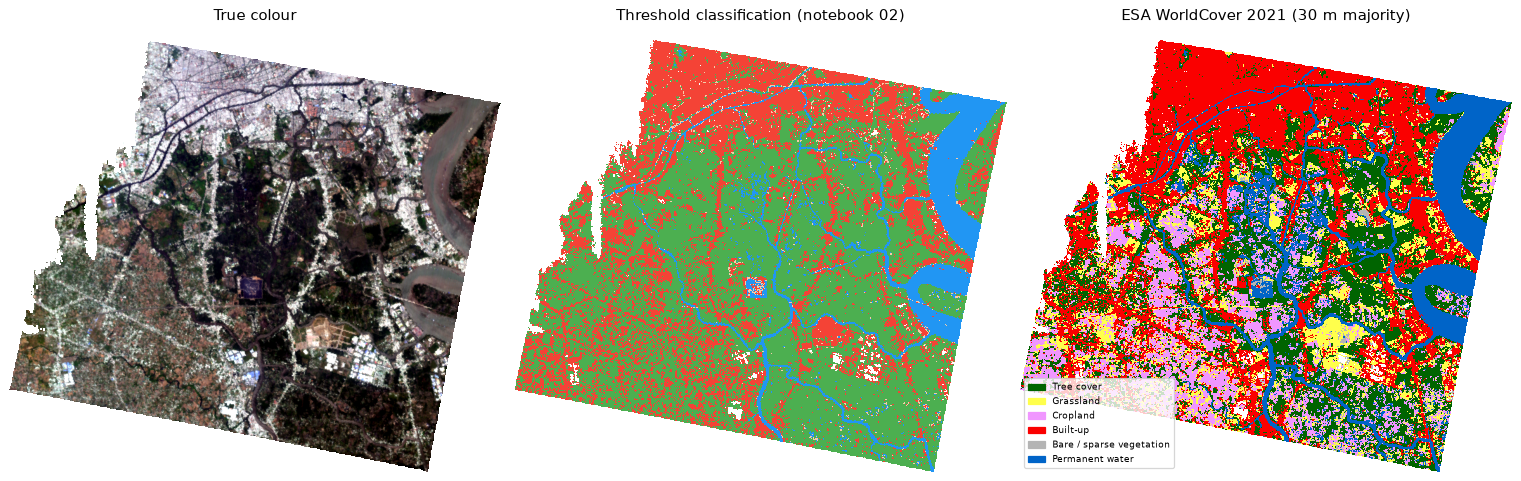

In [2]:
import pandas as pd

SCENE_ID = "20250407_035509_25_4001"   # Ho Chi Minh City, Vietnam (urban), 7 April 2025
scene = hu.get_scene(SCENE_ID)
print(scene.summary())

valid = scene.valid_mask()
R_green, R_red, R_nir, R_swir = (scene.read_band(w) for w in (560, 665, 830, 1610))   # as in notebook 02
NDVI = hu.nd(R_nir, R_red)
NDBI = hu.nd(R_swir, R_nir)
MNDWI = hu.nd(R_green, R_swir)
PIXEL_HA = 0.09

# The threshold classification of notebook 02 (same rules, same order)
CLASSES = ["Water", "Vegetation", "Built-up", "Bare soil"]
lc = np.full(NDVI.shape, 255, dtype=np.uint8)
lc[MNDWI > 0.1] = 0
lc[NDVI > 0.2] = 1
lc[NDBI > 0.0] = 2
lc[(NDBI <= 0) & (NDVI <= 0.2) & (MNDWI <= 0.1)] = 3
lc[~valid] = 255

# ESA WorldCover 2021 on the Tanager grid: majority class + purity (how many of the nine 10 m cells agree)
wc, purity = hu.load_labels(SCENE_ID)

from matplotlib.colors import ListedColormap
CMAP4 = ListedColormap(["#2196F3", "#4CAF50", "#F44336", "#F5CBA7"])
wc_cmap, wc_norm, wc_handles = hu.label_cmap([10, 30, 40, 50, 60, 80])
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
axes[0].imshow(scene.rgb()); axes[0].set_title("True colour")
axes[1].imshow(np.where(lc == 255, np.nan, lc), cmap=CMAP4, vmin=0, vmax=3, interpolation="nearest")
axes[1].set_title("Threshold classification (notebook 02)")
axes[2].imshow(np.where(valid & (wc > 0), wc, np.nan), cmap=wc_cmap, norm=wc_norm, interpolation="nearest")
axes[2].set_title("ESA WorldCover 2021 (30 m majority)")
axes[2].legend(handles=wc_handles, loc="lower left", fontsize=7)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Exercise 1 — Land-cover statistics in km²  ⭐

Using the threshold map `lc` (0 = water, 1 = vegetation, 2 = built-up, 3 = bare soil, 255 = no data):

1. Make a small table (pandas `DataFrame`) with the pixel count, area in km² and % of the valid area per class.
2. Ho Chi Minh City is one of the most densely built cities in Southeast Asia — does the built-up share
   surprise you? Look at the true-colour image: which part of the scene is the dense city?

### Solution

In [3]:
classes, counts = np.unique(lc[valid], return_counts=True)
table = pd.DataFrame({"class": [CLASSES[c] for c in classes], "pixels": counts,
                      "area_km2": counts * PIXEL_HA / 100, "percent": 100 * counts / valid.sum()})
table.round(1)

,class,pixels,area_km2,percent
0,Water,34427,31.0,9.5
1,Vegetation,208977,188.1,57.8
2,Built-up,113553,102.2,31.4
3,Bare soil,4423,4.0,1.2


**Interpretation:** vegetation and built-up each cover roughly a third of the valid area, water about 13%.
The scene covers the **southern outskirts** of Ho Chi Minh City: the dense urban core is in the north,
while the centre and south are a mosaic of peri-urban villages, gardens, fishponds, industrial parks and the
Saigon–Nhà Bè river system. "Bare soil" is almost absent because in this humid climate most open land is
vegetated or built.

## Exercise 2 — How well do the thresholds agree with WorldCover?  ⭐⭐

Compare the threshold map with ESA WorldCover (2021) on **pure** pixels only (`purity == 9`, i.e. all nine
10 m WorldCover cells inside the 30 m pixel have the same class).

1. Translate the WorldCover classes to the four classes: 80 → Water; 10, 20, 30, 40, 90, 95 → Vegetation;
   50 → Built-up; 60 → Bare soil.
2. Build a confusion matrix (rows = WorldCover, columns = thresholds) and compute the overall agreement and
   the per-class *recall* (the fraction of each WorldCover class that the thresholds got right).
3. Which confusion dominates? Look at where it happens on the map.

We say **agreement**, not accuracy: WorldCover is a 2021 product with its own errors, and the city has changed.

### Solution

Thresholds,Bare soil,Built-up,Vegetation,Water
WorldCover,,,,
Bare soil,77,483,390,65
Built-up,1426,67094,16851,25
Vegetation,296,18479,81915,438
Water,609,381,6722,30994


Overall agreement on 226,245 pure pixels: 79.6%
Recall per WorldCover class:
WorldCover
Bare soil     0.076
Built-up      0.786
Vegetation    0.810
Water         0.801


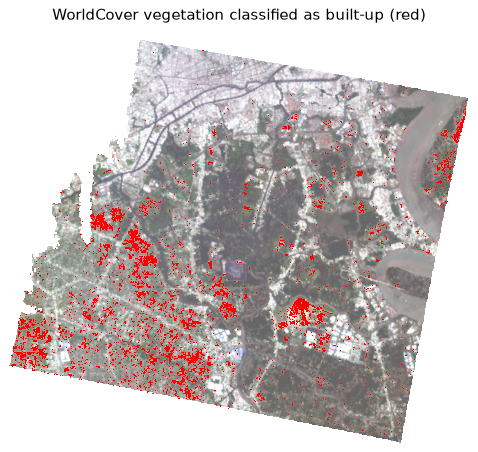

In [4]:
TO4 = {80: 0, 10: 1, 20: 1, 30: 1, 40: 1, 90: 1, 95: 1, 50: 2, 60: 3}
ref = np.full(wc.shape, 255, dtype=np.uint8)
for code, cls in TO4.items():
    ref[wc == code] = cls
ok = valid & (purity == 9) & (ref != 255) & (lc != 255)

cm = pd.crosstab(pd.Series(ref[ok], name="WorldCover").map(dict(enumerate(CLASSES))),
                 pd.Series(lc[ok], name="Thresholds").map(dict(enumerate(CLASSES))))
display(cm)
agreement = (ref[ok] == lc[ok]).mean()
recall = pd.Series(np.diag(cm.loc[cm.index, cm.index]) / cm.sum(axis=1), index=cm.index)
print(f"Overall agreement on {ok.sum():,} pure pixels: {agreement:.1%}")
print("Recall per WorldCover class:"); print(recall.round(3).to_string())

confused = ok & (ref == 1) & (lc == 2)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(scene.rgb(), alpha=0.6)
ax.imshow(np.where(confused, 1, np.nan), cmap="autumn", interpolation="nearest")
ax.set_title("WorldCover vegetation classified as built-up (red)"); ax.axis("off")
plt.show()

**Interpretation:** about 80% of the pure pixels agree. Water is recovered well. The dominant confusion is
**vegetation ↔ built-up** in both directions. The rule order in notebook 02 lets `NDBI > 0` overwrite
`NDVI > 0.2`, so vegetated pixels with bright soil or roofs in view become "built-up". Conversely, built-up
pixels with trees or gardens stay "vegetation". The red pixels cluster in the peri-urban villages, where 10 m
WorldCover sees trees between houses that a 30 m index averages. "Bare soil" is nearly always wrong: the
thresholds call very few pixels bare, and WorldCover's few bare pixels are mostly construction sites.

## Exercise 3 — Choosing the NDBI threshold from data  ⭐⭐

The value `NDBI > 0` is a textbook default. Find the threshold that best reproduces WorldCover **built-up**
(class 50) on pure pixels:

1. For thresholds from −0.25 to 0.15 (step 0.025), compute precision, recall and F1 of `NDBI > t` against
   WorldCover built-up.
2. Plot the three curves and mark the best-F1 threshold.
3. Is the "best" threshold transferable to another city? Why (not)?

### Solution

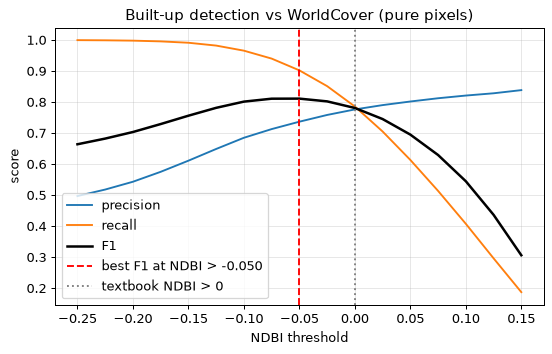

best threshold -0.050: F1 = 0.811   (NDBI > 0: F1 = 0.781)


In [5]:
ok = valid & (purity == 9) & (wc > 0)
truth = (wc == 50)[ok]
ndbi = NDBI[ok]
ts = np.arange(-0.25, 0.151, 0.025)
P, Rc, F = [], [], []
for t in ts:
    pred = ndbi > t
    tp = (pred & truth).sum()
    p, r = tp / max(pred.sum(), 1), tp / truth.sum()
    P.append(p); Rc.append(r); F.append(2 * p * r / (p + r + 1e-12))
best = ts[int(np.argmax(F))]

plt.figure(figsize=(7, 4))
plt.plot(ts, P, label="precision"); plt.plot(ts, Rc, label="recall"); plt.plot(ts, F, "k", lw=2, label="F1")
plt.axvline(best, color="r", ls="--", label=f"best F1 at NDBI > {best:.3f}")
plt.axvline(0, color="grey", ls=":", label="textbook NDBI > 0")
plt.xlabel("NDBI threshold"); plt.ylabel("score"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Built-up detection vs WorldCover (pure pixels)")
plt.show()
print(f"best threshold {best:.3f}: F1 = {max(F):.3f}   (NDBI > 0: F1 = {F[int(np.argmin(np.abs(ts)))]:.3f})")

**Interpretation:** the best F1 is reached slightly *below* zero (around −0.05 to −0.1), not at the textbook
value, and the F1 curve is fairly flat near its optimum. The gain over `NDBI > 0` is modest here, but in
other cities it can be large: NDBI depends on roof materials (concrete, metal, tiles), soil colour, climate
(dry desert soils have a high NDBI too — a classic problem in Arab cities) and even on which exact bands you
use. A threshold tuned against a reference map is a **model fitted to that scene**. Tune it on one part of
the data and report the score on another (Week 3: validation).

## Exercise 4 — Let the spectra speak: k-means instead of thresholds  ⭐⭐⭐

Replace the hand-made thresholds by unsupervised clustering on the **full spectrum**:

1. Read the whole scene with `stride=2` (every 2nd pixel, to save memory) and reduce it to 15 PCA components.
2. Run k-means with k = 10 (more clusters than classes: several spectral clusters can map to one class).
3. Give each cluster the four-class label that is most common among its pure WorldCover pixels
   (majority vote) — this uses the reference only to *name* clusters, not to train them.
4. Compute the agreement with WorldCover on pure pixels, as in Exercise 2, and compare it with the thresholds
   on the same stride-2 grid.

Is it a fair comparison? What information did the clustering use that the thresholds did not?

### Solution

cluster → class: {0: 'Built-up', 1: 'Vegetation', 2: 'Water', 3: 'Built-up', 4: 'Vegetation', 5: 'Built-up', 6: 'Built-up', 7: 'Vegetation', 8: 'Vegetation', 9: 'Vegetation'}
agreement k-means + majority naming: 82.9%
agreement thresholds (notebook 02):  79.7%


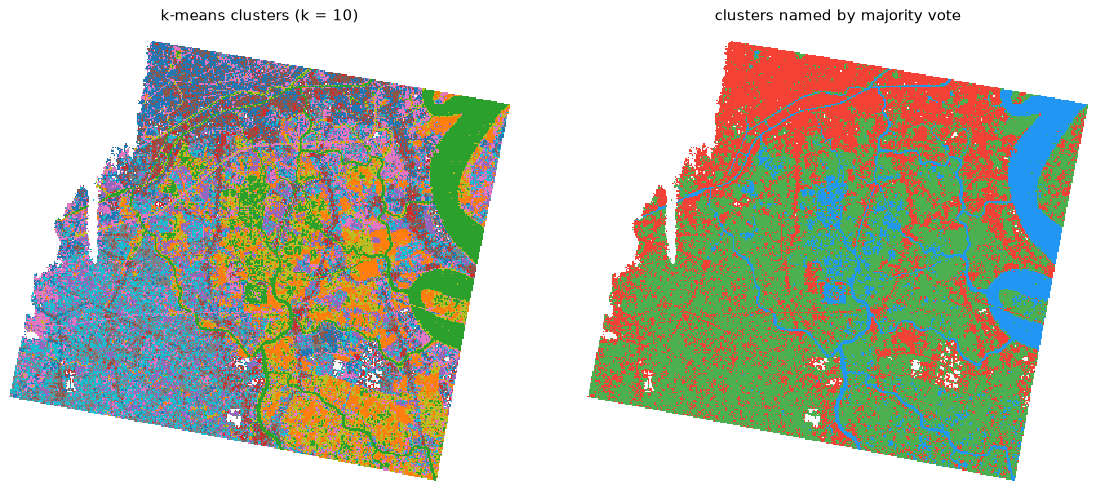

In [6]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

cube, wl = scene.read_cube(stride=2)
X, okpix = hu.cube_to_pixels(cube)
del cube
rng = np.random.default_rng(0)
fit_idx = rng.choice(len(X), size=30_000, replace=False)
pca = PCA(n_components=15, random_state=0).fit(X[fit_idx])
km = KMeans(n_clusters=10, n_init=10, random_state=0).fit(pca.transform(X[fit_idx]))
clusters = hu.pixels_to_image(km.predict(pca.transform(X)).astype(float), okpix)

TO4 = {80: 0, 10: 1, 20: 1, 30: 1, 40: 1, 90: 1, 95: 1, 50: 2, 60: 3}
ref = np.full(wc.shape, 255, dtype=np.uint8)
for code, cls in TO4.items():
    ref[wc == code] = cls
ref2, pur2, lc2 = ref[::2, ::2], purity[::2, ::2], lc[::2, ::2]
pure = np.isfinite(clusters) & (pur2 == 9) & (ref2 != 255)

cluster_to_class = {}
for k in range(10):
    votes = ref2[pure & (clusters == k)]
    cluster_to_class[k] = int(np.bincount(votes, minlength=4).argmax()) if votes.size else 3
km_map = np.full(clusters.shape, 255, dtype=np.uint8)
for k, c in cluster_to_class.items():
    km_map[clusters == k] = c
print("cluster → class:", {k: CLASSES[c] for k, c in cluster_to_class.items()})

both = pure & (lc2 != 255)
print(f"agreement k-means + majority naming: {(km_map[both] == ref2[both]).mean():.1%}")
print(f"agreement thresholds (notebook 02):  {(lc2[both] == ref2[both]).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].imshow(clusters, cmap="tab10", interpolation="nearest"); axes[0].set_title("k-means clusters (k = 10)")
axes[1].imshow(np.where(km_map == 255, np.nan, km_map), cmap=CMAP4, vmin=0, vmax=3, interpolation="nearest")
axes[1].set_title("clusters named by majority vote")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

**Interpretation:** compare the two agreement numbers printed above. Clustering on all ~350 bands usually
matches or beats the three-index thresholds, because it can use the whole spectral shape: roof materials,
water turbidity and vegetation types each form their own clusters, and several clusters can be merged into one
class. The comparison is **not entirely fair**, though. The majority vote *looked at the reference labels* to
name the clusters, so the score is optimistic. For a fair estimate you would name the clusters with labels from
one part of the scene and evaluate on another, or with labels from field work. That is the essence of the
train/test split in Week 3.

## Exercise 5 — Roof and pavement materials  ⭐⭐

"Built-up" is not one material. Within WorldCover built-up pixels (class 50, NDVI < 0.15) select three groups:

- **bright roofs**: the brightest 1% (mean reflectance of 480, 550, 665, 830 and 1610 nm);
- **red / orange surfaces**: the top 0.5% of the ratio R₆₄₀ / R₅₅₀ among pixels brighter than the median;
- **dark surfaces**: the darkest 5%.

Plot the mean spectrum of each group plus a tree-cover reference (WorldCover 10, NDVI > 0.7). Which spectral
features could tell the materials apart, and which dips are *not* material features at all?

### Solution

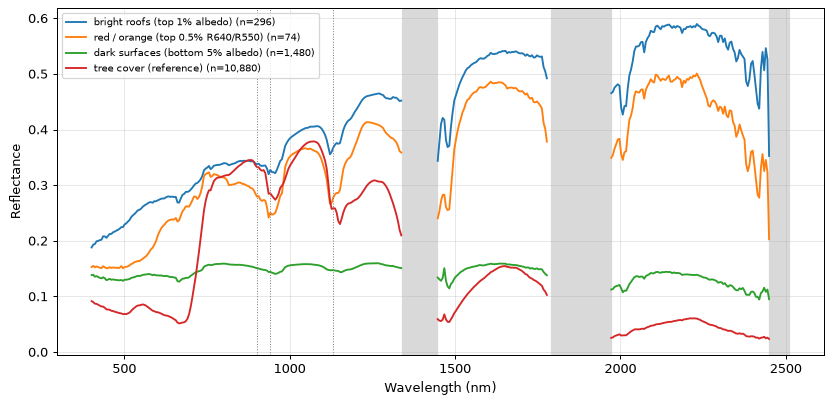

In [7]:
B = {w: scene.read_band(w) for w in (480, 550, 640, 665, 830, 1610)}
albedo = np.mean([B[w] for w in (480, 550, 665, 830, 1610)], axis=0)
built = valid & (wc == 50) & (NDVI < 0.15)
redness = B[640] / B[550]
bright_half = built & (albedo > np.nanmedian(albedo[built]))
groups = {
    "bright roofs (top 1% albedo)": built & (albedo > np.nanpercentile(albedo[built], 99)),
    "red / orange (top 0.5% R640/R550)": bright_half & (redness > np.nanpercentile(redness[bright_half], 99.5)),
    "dark surfaces (bottom 5% albedo)": built & (albedo < np.nanpercentile(albedo[built], 5)),
    "tree cover (reference)": valid & (wc == 10) & (NDVI > 0.7),
}

def mean_spectrum(mask, max_px=500):
    rows, cols = np.nonzero(mask)
    pick = np.random.default_rng(0).choice(len(rows), size=min(max_px, len(rows)), replace=False)
    rows, cols = rows[pick], cols[pick]
    cube, wl = scene.read_cube((rows.min(), rows.max() + 1, cols.min(), cols.max() + 1))
    return np.nanmean(cube[:, rows - rows.min(), cols - cols.min()], axis=1), wl

fig, ax = plt.subplots(figsize=(11, 5))
hu.shade_bad_regions(ax)
for name, m in groups.items():
    spec, wl = mean_spectrum(m)
    hu.plot_spectrum(ax, wl, spec, label=f"{name} (n={m.sum():,})")
for w in (900, 940, 1130):
    ax.axvline(w, color="grey", ls=":", lw=0.8)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

**Interpretation**
- **Bright roofs** (metal sheets and white coatings on warehouses) are bright and fairly flat across the
  SWIR — high albedo, with no vegetation or strong mineral features.
- **Red / orange surfaces** — clay-tile roofs and exposed lateritic soil on construction sites — have a steep
  rise from 500 to 600 nm and a broad trough around 850–950 nm. Both are **iron-oxide** (Fe³⁺) absorptions,
  which makes this a real material fingerprint that hyperspectral data can map.
- **Dark surfaces** (asphalt, dark roofs, shadows) are uniformly low. Distinguishing asphalt from shadow
  needs the SWIR shape and context.
- The narrow dips at ~940 and ~1130 nm, visible in the bright spectra, are **residual atmospheric water
  vapour**, not material features. They appear wherever the surface is bright, so don't interpret them as
  materials.

Mapping roofing materials (e.g. asbestos-cement vs metal vs tiles) is a real application — informal
settlement mapping, heat-risk and hail-damage assessment — but at 30 m most pixels mix several roofs, so
spectral **unmixing** (Week 2, material discrimination) is the right tool.

## Exercise 6 — Reflection — what does '80% agreement' mean?  ⭐

Answer in a short markdown cell:

1. List three reasons why the threshold map and WorldCover can disagree even where the threshold map is right.
2. What share of the valid pixels are *pure* (purity = 9)? Why did we evaluate only on pure pixels — and what
   bias does that introduce into the agreement score?

### Solution

In [8]:
print(f"pure pixels: {(purity[valid] == 9).mean():.1%} of the valid scene")

pure pixels: 62.6% of the valid scene


**Model answer**
1. (a) **Time:** WorldCover shows 2021, while Tanager saw April 2025, and peri-urban Ho Chi Minh City changes
   fast (new industrial parks, filled ponds). (b) **Resolution and definitions:** a 30 m pixel with houses under
   trees is "tree cover" at 10 m but spectrally mixed at 30 m. (c) **Reference errors:** WorldCover's own
   global accuracy is about 75%, and it is lower for built-up in dense tropical settlements. (d) **Georegistration**
   offsets of a fraction of a pixel matter along edges.
2. Only about 60% of the valid pixels are pure. Evaluating on pure pixels removes edges and mixed pixels —
   exactly the hard cases — so the score is **optimistic** and applies to homogeneous areas only. Report it as
   "agreement on homogeneous reference pixels", and use a proper sampling design (Week 3, accuracy assessment)
   for a statistically valid map accuracy.

## Key takeaways

- Always compare a map with an independent reference — and call it agreement unless the reference is ground truth.
- Index thresholds are scene-specific models; tune them on one part of the data and test on another.
- Full-spectrum clustering captures materials that three indices cannot.
- 'Built-up' contains distinct materials (metal, tiles, asphalt) with diagnostic features such as iron-oxide absorption.
- Evaluating only on pure pixels gives optimistic scores.

---

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC  
> 📖 Labels: ESA WorldCover 2021 v200 — CC-BY 4.0